# Cellohood Analyses - Spleen Codex

In this notebook we will reproduce results for the analysis of Spleen CODEX dataset.

## Data Preparation

Download Cellohood artifacts from zenodo: #TODO. Then set `ZENODO_PATH` to a path to zenodo Spleen Codex Cellohood artifacts. This will ensure that all model / analyses artifacts will be reproducible:

In [1]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = ''

import pandas
import joblib

from ccs import ccs
import cellohood


ZENODO_PATH = '/raid/immucan/immuw/cellohood_artifacts/SPLEEN/'


DATA_PATH = os.path.join(ZENODO_PATH, 'spleen.df')
data_df = pandas.read_csv(DATA_PATH)


MARKER_COL_NAMES = [
    'CD45', 
    'Ly6C', 
    'TCR', 
    'Ly6G', 
    'CD19', 
    'CD169', 
    'CD106', 
    'CD3', 
    'CD1632', 
    'CD8a', 
    'CD90', 
    'F480', 
    'CD11c', 
    'Ter119', 
    'CD11b', 
    'IgD', 
    'CD27', 
    'CD5', 
    'CD79b', 
    'CD71', 
    'CD31', 
    'CD4', 
    'IgM', 
    'B220', 
    'ERTR7', 
    'CD35', 
    'CD2135', 
    'CD44', 
    'NKp46', 
    'MHCII', 

]


DISTANCE_THRESHOLD = 100.
POS_COL_NAMES = ['tile.X', 'tile.Y']
IMAGE_ID_COLUMN = 'sample'
SAMPLE_COL_NAME = 'sample'

LOAD_CELLO_BAG_DF = True
FULL_CELLO_BAG_DF_PATH = os.path.join(ZENODO_PATH, 'SpleenBCDf')

TRAIN_MODEL = False
SAVING_PATH = os.path.join(ZENODO_PATH, 'SPLEEN_CM')

LOAD_CELLO_PREDICTION = True
CELLO_PREDICTION_PATH = os.path.join(ZENODO_PATH, 'SPLEEN_CP')

TRAIN_LATENT_DIRECTIONS = False
LD_SAVING_PATH = os.path.join(ZENODO_PATH, 'spleen_ld.pickle')

/tmp/ipykernel_2526670/1651024944.py:16: DtypeWarning: Columns (48,49) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pandas.read_csv(DATA_PATH)


Now - let's load `CelloBagDf` - containing cell representations, positions, and bag ids:

In [2]:
TRAIN_LATENT_DIRECTIONS = False
LD_SAVING_PATH = os.path.join(ZENODO_PATH, 'spleen_ld.pickle')

Let's split the data into training / test splits. They are split by samples - so it's omitted for small datasets (by setting the `split_percentage` to `1.0`:

In [3]:
if not LOAD_CELLO_BAG_DF:
    bag_cello_df = cellohood.transform_df_to_bag_cello_df(
        df_=data_df,
        image_id_column=IMAGE_ID_COLUMN,
        pos_col_names=POS_COL_NAMES,
        distance_threshold=DISTANCE_THRESHOLD,
        marker_col_names=MARKER_COL_NAMES,
    )
    cellohood.save_bag_cello_df(bag_cello_df=bag_cello_df, path=FULL_CELLO_BAG_DF_PATH, exist_ok=True)
else:
    bag_cello_df = cellohood.load_bag_cello_df(path=FULL_CELLO_BAG_DF_PATH)

/raid/immucan/immuw/cellohood/cellohood/data_processing/data_transforms.py:384: DtypeWarning: Columns (49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pandas.read_csv(df_path)


Let's split the data into training / test splits. They are split by samples - so it's omitted for small datasets (by setting the `split_percentage` to `1.0`:

In [4]:
train_bag_cello_df, test_bag_cello_df = cellohood.split_bag_cello_df_by(
    bag_cello_df,
    by=SAMPLE_COL_NAME,
    split_percentage=1.,
)

Now - let's standardize the data:

In [5]:
standardized_cello_dfs = cellohood.standardize_bag_cello_df(
    train_bag_cello_df=train_bag_cello_df, 
    test_bag_cello_df=test_bag_cello_df,
    marker_col_names=MARKER_COL_NAMES,
)

Now - let's train / load the model (by default it's loading a model from Cellohood zenodo artifacts):

In [6]:
if TRAIN_MODEL:
    cello_train_result = cellohood.train(
        standardized_cello_dfs=standardized_cello_dfs,
        epoch_nb=100,
        use_cuda=True,
    )
    cellohood.save_cello_train_result(cello_train_result, SAVING_PATH)
else:
    cello_train_result = cellohood.load_cello_train_result(SAVING_PATH)

{'output_size': 30, 'max_neighborhood_size': 15, 'latent_size': 64, 'layer_size': 128, 'intermediate_layer_size': 256}


2025-11-28 15:26:38.928920: E tensorflow/stream_executor/cuda/cuda_driver.cc:271] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2025-11-28 15:26:38.928969: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:169] retrieving CUDA diagnostic information for host: rudy
2025-11-28 15:26:38.928976: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:176] hostname: rudy
2025-11-28 15:26:38.929193: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:200] libcuda reported version is: 535.230.2
2025-11-28 15:26:38.929224: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:204] kernel reported version is: 535.230.2
2025-11-28 15:26:38.929229: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:310] kernel version seems to match DSO: 535.230.2
/raid/immucan/immuw/cellohood_venv/lib/python3.8/site-packages/keras/engine/training_v1.py:2079: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorF

Now - let's load / prepare Cellohood predictions:

In [7]:
if not LOAD_CELLO_PREDICTION:
    cello_prediction = cellohood.run_prediction_on_cello_df(
        cello_train_result,
        bag_cello_df,
    )
    !rm -r new_cache
    smoothed_df_result = cellohood.smooth_cellohood_prediction(
        cello_prediction,
        distance_threshold=DISTANCE_THRESHOLD,
        cache_path='new_cache',
    )
    !rm -r new_cache
    cellohood.save_cello_prediction(
        cello_prediction=smoothed_df_result,
        path=CELLO_PREDICTION_PATH,
    )
else: 
    smoothed_df_result = cellohood.load_cello_prediction(
        path=CELLO_PREDICTION_PATH,
    )

In [8]:
if TRAIN_LATENT_DIRECTIONS:
    latent_direction_result = cellohood.get_latent_directions(
        df=smoothed_df_result.bag_predictions,
        columns=smoothed_df_result.cello_columns,
        explained_variance_levels=(0.5, 0.75, 1.0),
        min_nb_of_clusters=5,
        max_nb_of_clusters=30,
        nb_of_tries_per_cluster_nb=5,
        take_every_example_for_training=100,
        clusters_step=1,
    )
    joblib.dump(latent_direction_result, LD_SAVING_PATH)
else:
    latent_direction_result = joblib.load(LD_SAVING_PATH)

As we may see - the coarse resolution (variance = 0.5) uses 3 PLDs:

In [9]:
cellohood.summarize_latent_direction_result(latent_direction_result)

Latent Direction Summary:
Variance: 0.5 (dim=3), selected clusters = [11, 16, 24].
Variance: 0.75 (dim=12), selected clusters = [18].
Variance: 1.0 (dim=64), selected clusters = [11, 14, 18, 21, 26].


For compartment clustering:

In [10]:
from sklearn.decomposition import PCA


decomposer = PCA()
decomposed = decomposer.fit_transform(
    smoothed_df_result.cell_predictions[smoothed_df_result.cello_columns].values,    
)

## Plotting setup

In [11]:
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import numpy
from collections import defaultdict
from matplotlib import colors as mcolors
from matplotlib.colors import LinearSegmentedColormap


# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

# Uncomment for Arial font (set the path to downloaded Arial.ttf)
# ARIAL_PATH = ..
# matplotlib.font_manager.fontManager.addfont(ARIAL_PATH)  # if you need to add the font file
# plt.rcParams['font.family'] = 'Arial'


COMPARTMENT_TO_COLOR = defaultdict(lambda: mcolors.CSS4_COLORS['white'])

COMPARTMENT_TO_COLOR['B-zone'] = mcolors.BASE_COLORS['k']
COMPARTMENT_TO_COLOR['PALS'] = mcolors.BASE_COLORS['b']
COMPARTMENT_TO_COLOR['marginal zone'] = mcolors.CSS4_COLORS['yellow']
COMPARTMENT_TO_COLOR['red pulp'] = mcolors.CSS4_COLORS['red']
COMPARTMENT_TO_COLOR['NoAnnotation'] = mcolors.CSS4_COLORS['white']
COMPARTMENT_TO_COLOR[numpy.nan] = mcolors.CSS4_COLORS['white']


colors_cc = LinearSegmentedColormap.from_list('clusters', list(COMPARTMENT_TO_COLOR.values()), N=6)

## Compartment clustering:

### Cellohood:

First, let's prepare `BALBc*` samples for which we have a ground truth compartment assignments:

In [12]:
balbc_samples_df_all = bag_cello_df.cell_df[
    bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB'))
].copy()
balbc_decomposed = decomposed[
    bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')).values
]

For metrics computations let's assign integer values to compartments:

In [13]:
import numpy


compartments = [
    'B-zone', 'PALS', 'marginal zone', 'red pulp',  'NoAnnotation', numpy.nan
]

balbc_samples_df_all['CompartmentValidInt'] = balbc_samples_df_all['Compartment'].apply(lambda x: compartments.index(x))

Now - let's run a `ccs` for selecting number of clusters and clustering:

In [14]:
import pickle


import ccs


LOAD_CELLOHOOD_CLUSTERERS = True
cellohood_clusterers_path = os.path.join(ZENODO_PATH, 'cellohood_clusterers')
os.makedirs(cellohood_clusterers_path, exist_ok=True)


balbc_samples = set(balbc_samples_df_all['sample'])

sample_to_ccs_result = {}

for sample in balbc_samples:
    output_file = os.path.join(cellohood_clusterers_path, f"{sample}.pickle")

    if not LOAD_CELLOHOOD_CLUSTERERS:
        # --- RUN AND SAVE ---
        result = ccs.cellohood_cluster_selection(
            x=balbc_decomposed[balbc_samples_df_all['sample'] == sample, :3],
            clusters_to_analyze=list(range(2, 10)),
        )

        # save result
        with open(output_file, "wb") as f:
            pickle.dump(result, f)

    else:
        # --- LOAD FROM DISK ---
        if not os.path.exists(output_file):
            raise FileNotFoundError(
                f"Expected file '{output_file}' not found. "
                "Run with LOAD_CELLOHOOD_CLUSTERERS=False first."
            )
        with open(output_file, "rb") as f:
            result = pickle.load(f)

    # store
    sample_to_ccs_result[sample] = result

As we may see - for all of the samples algorithm selected 4 clusters:

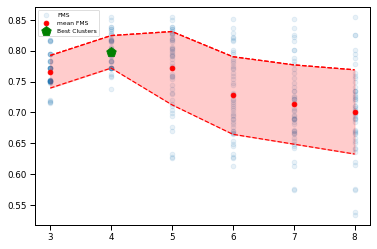

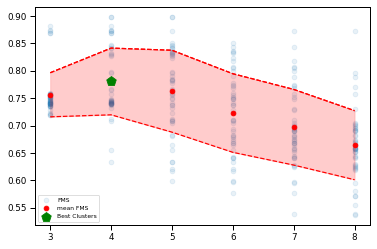

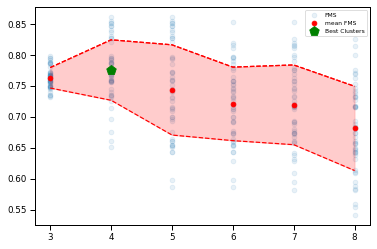

In [15]:
import matplotlib.pyplot as plt


for sample in balbc_samples:
    ccs.plot_ccs_result(sample_to_ccs_result[sample])
    plt.show()

In [16]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import adjusted_mutual_info_score as ami
from sklearn.metrics import f1_score 
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

sample_amis, sample_f1s, sample_aris = [], [], []

sample_to_predictions = {}

NB_OF_CLUSTERS = 4


for sample in set(balbc_samples_df_all['sample']):
    print(sample)
    sample_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == sample]
    sample_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == sample]
    bci = numpy.argmin([cl.inertia_ for cl in sample_to_ccs_result[sample].cluster_nb_to_k_means[4]])
    classes = sample_to_ccs_result[sample].cluster_nb_to_predictions[4][bci]

    classes_dict = {
        cl: sample_df['CompartmentValidInt'][classes == cl].mode().values[0]
        for cl in range(NB_OF_CLUSTERS)
    }
    
    print(classes_dict)
    corrected_classes = numpy.array([classes_dict[x] for x in classes])
    sample_to_predictions[sample] = corrected_classes
    
    sample_amis.append(
        ami(
            sample_df['Compartment'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
            classes[sample_df['CompartmentValidInt'].isin(list(range(4)))]
        )
    )
    sample_f1s.append(f1_score(
        sample_df['CompartmentValidInt'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
        corrected_classes[sample_df['CompartmentValidInt'].isin(list(range(4))).values],
        average='macro',
    ))
    sample_aris.append(
        adjusted_rand_score(
            sample_df['Compartment'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
            classes[sample_df['CompartmentValidInt'].isin(list(range(4)))]
        )
    )

BALBc-3
{0: 0, 1: 3, 2: 1, 3: 2}
BALBc-1
{0: 1, 1: 0, 2: 3, 3: 2}
BALBc-2
{0: 2, 1: 1, 2: 3, 3: 0}


In [17]:
sample_df['ClassPredicted'] = classes

/tmp/ipykernel_2526670/3318338133.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sample_df['ClassPredicted'] = classes


## Aggregated Cell Bag representation

For aggregated cell bag representations, let's first compute aggregated marker statistics:

In [18]:
mean_markers = balbc_samples_df_all.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].mean()
max_markers = balbc_samples_df_all.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].max()
min_markers = balbc_samples_df_all.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].min()

In [19]:
agg_markers = pandas.concat([mean_markers, max_markers, min_markers], axis=1)

In [20]:
mean_marker_samples = balbc_samples_df_all.groupby('cellohood_neighborhood_cluster')['sample'].first()

Now, let's run the clustering:

In [21]:
LOAD_AGG_CBR_CLUSTERERS = True
agg_cbr_path = os.path.join(ZENODO_PATH, 'agg_cbr_clusterers')


sample_to_ccs_result_agr_cbr = {}

for sample in balbc_samples:
    output_file = os.path.join(agg_cbr_path, f"{sample}.pickle")

    if not LOAD_AGG_CBR_CLUSTERERS:
        # --- RUN AND SAVE ---
        result = ccs.cellohood_cluster_selection(
            x=agg_markers[mean_marker_samples == sample],
            clusters_to_analyze=list(range(2, 10)),
        )

        # save result
        with open(output_file, "wb") as f:
            pickle.dump(result, f)

    else:
        # --- LOAD FROM DISK ---
        if not os.path.exists(output_file):
            raise FileNotFoundError(
                f"Expected file '{output_file}' not found. "
                "Run with LOAD_AGG_CBR_CLUSTERERS=False first."
            )
        with open(output_file, "rb") as f:
            result = pickle.load(f)

    # store
    sample_to_ccs_result_agr_cbr[sample] = result

Interestingly - for one of the samples - algorithm found 5 clusters:

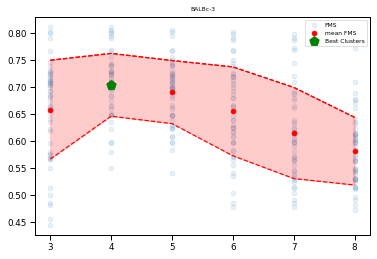

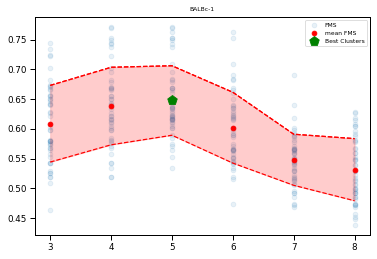

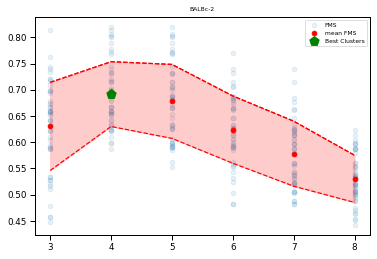

In [22]:
for sample in balbc_samples:
    ccs.plot_ccs_result(sample_to_ccs_result_agr_cbr[sample])
    plt.title(sample)
    plt.show()

Now, let's compute predictions and metrics:

In [23]:
sample_to_predictions_agg_cbr = {}

for sample in balbc_samples:
    best_clusterer_ind = 4 if 4 in sample_to_ccs_result_agr_cbr[sample].best_clusterers else 5
    raw_cc = balbc_samples_df_all[balbc_samples_df_all['sample'] == sample]['cellohood_neighborhood_cluster']
    raw_cc = raw_cc - raw_cc.iloc[0]
    raw_predictions = sample_to_ccs_result_agr_cbr[sample].best_clusterers[
        best_clusterer_ind
    ].predict(agg_markers[mean_marker_samples == sample])
    sample_to_predictions_agg_cbr[sample] = numpy.array([raw_predictions[i] for i in raw_cc])

In [24]:
sample_amis_agg_cbr, sample_f1s_agg_cbr = [], []


for sample in set(balbc_samples_df_all['sample']):
    best_clusterer_ind = 4 if 4 in sample_to_ccs_result_agr_cbr[sample].best_clusterers else 5
    sample_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == sample]
    classes = sample_to_predictions_agg_cbr[sample]

    classes_dict = {
        cl: sample_df['CompartmentValidInt'][classes == cl].mode().values[0]
        for cl in range(best_clusterer_ind)
    }
    
    corrected_classes = numpy.array([classes_dict[x] for x in classes])
    sample_to_predictions_agg_cbr[sample] = corrected_classes
    
    sample_amis_agg_cbr.append(
        ami(
            sample_df['Compartment'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
            classes[sample_df['CompartmentValidInt'].isin(list(range(4)))]
        )
    )
    sample_f1s_agg_cbr.append(f1_score(
        sample_df['CompartmentValidInt'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
        corrected_classes[sample_df['CompartmentValidInt'].isin(list(range(4))).values],
        average='macro',
    ))

### Aggregated cell type histogram representations:

Let's start with computation of appropriate cell type histograms:

In [25]:
DUMMY_COL_NAME = 'Dummy'

balbc_samples_df_all[DUMMY_COL_NAME] = 1

In [26]:
celltype_histogram = pandas.pivot_table(
    balbc_samples_df_all,
    values=DUMMY_COL_NAME,
    columns='celltype',
    index='cellohood_neighborhood_cluster',
    aggfunc='sum',
).fillna(0)

celltype_histogram = (celltype_histogram.T / celltype_histogram.T.sum(axis=0)).T

In [27]:
LOAD_AGG_CTH_CLUSTERERS = True
agg_cth_path = os.path.join(ZENODO_PATH, 'agg_cth_clusterers')


sample_to_ccs_result_agg_cth = {}

for sample in balbc_samples:
    output_file = os.path.join(agg_cth_path, f"{sample}.pickle")

    if not LOAD_AGG_CTH_CLUSTERERS:
        # --- RUN AND SAVE ---
        result = ccs.cellohood_cluster_selection(
            x=celltype_histogram[mean_marker_samples == sample],
            clusters_to_analyze=list(range(2, 10)),
        )

        # save result
        with open(output_file, "wb") as f:
            pickle.dump(result, f)

    else:
        # --- LOAD FROM DISK ---
        if not os.path.exists(output_file):
            raise FileNotFoundError(
                f"Expected file '{output_file}' not found. "
                "Run with LOAD_AGG_CTH_CLUSTERERS=False first."
            )
        with open(output_file, "rb") as f:
            result = pickle.load(f)

    # store
    sample_to_ccs_result_agg_cth[sample] = result

In [28]:
sample_to_predictions_cth = {}
sample_to_corrected_predictions_cth = {}

for sample in balbc_samples:
    best_clusterer_ind = 4 
    raw_cc = balbc_samples_df_all[balbc_samples_df_all['sample'] == sample]['cellohood_neighborhood_cluster']
    raw_cc = raw_cc - raw_cc.iloc[0]
    raw_predictions = sample_to_ccs_result_agg_cth[sample].best_clusterers[
        best_clusterer_ind
    ].predict(celltype_histogram[mean_marker_samples == sample])
    sample_to_predictions_cth[sample] = numpy.array([raw_predictions[i] for i in raw_cc])

In [29]:
sample_amis_cth, sample_f1s_cth = [], []


for sample in set(balbc_samples_df_all['sample']):
    best_clusterer_ind = 4
    sample_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == sample]
    classes = sample_to_predictions_cth[sample]

    classes_dict = {
        cl: sample_df['CompartmentValidInt'][classes == cl].mode().values[0]
        for cl in range(best_clusterer_ind)
    }
    
    corrected_classes = numpy.array([classes_dict[x] for x in classes])
    sample_to_corrected_predictions_cth[sample] = corrected_classes
    
    sample_amis_cth.append(
        ami(
            sample_df['Compartment'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
            classes[sample_df['CompartmentValidInt'].isin(list(range(4)))]
        )
    )
    sample_f1s_cth.append(f1_score(
        sample_df['CompartmentValidInt'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
        corrected_classes[sample_df['CompartmentValidInt'].isin(list(range(4))).values],
        average='macro',
    ))

### Metric comparison:

Let's load previous method results:

In [30]:
OTHER_METHOD_PATHS = '/raid/immucan/immuw/cellohood_artifacts/SPLEEN/other_methods/'

OTHER_METHOD_F1S_PATH = os.path.join(OTHER_METHOD_PATHS, 'other_f1s.df')
OTHER_METHOD_AMIS_PATH = os.path.join(OTHER_METHOD_PATHS, 'other_amis.df')

f1_scores_df = pandas.read_csv(OTHER_METHOD_F1S_PATH)
ami_scores_df = pandas.read_csv(OTHER_METHOD_AMIS_PATH)

and add our methods results:

In [31]:
f1_scores_df['Cellohood'] = sample_f1s
f1_scores_df['Agg.CBR'] = sample_f1s_agg_cbr
f1_scores_df['CTH.CBR'] = sample_f1s_cth

ami_scores_df['Cellohood'] = sample_amis
ami_scores_df['Agg.CBR'] = sample_amis_agg_cbr
ami_scores_df['CTH.CBR'] = sample_amis_cth

In [32]:
ami_scores_df.drop('Unnamed: 0', axis=1, inplace=True)
f1_scores_df.drop('Unnamed: 0', axis=1, inplace=True)

In [33]:
f1_scores_df = f1_scores_df[ami_scores_df.columns]

and visualize results:

In [34]:
method_cmap = plt.get_cmap('tab20', 7)



def AnnoMe(x1, x2, y, txt, h=0.005, offset=0, col='gray', fontsize=5, lw=0.5):
    plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=lw, c=col)
    plt.text((x1+x2)*.5, y+h - offset, '   ' + txt, ha='center', va='bottom', c=col, fontsize=fontsize)
    
    
    
def get_stars_from_pval(pval):
    pval_adj = f''
    if pval >= 0.01:
        pval_adj += f'={round(pval, 2)}'
    elif pval >= 0.001:
        pval_adj += f'={round(pval, 3)}'
    else:
        pval_adj += '<0.001'
    result = f'p{pval_adj} ('
    if pval < 0.05:
        result += '*'
    if pval < 0.01:
        result += '*'
    if pval < 0.001:
        result += '*'
    if pval >= 0.05:
        result += 'ns'
    return result + ')'

In [35]:
from scipy.stats import ttest_ind


ALTERNATIVE = 'greater'

f1s_p_vals = numpy.zeros((len(f1_scores_df.columns), len(f1_scores_df.columns)))
amis_p_vals = numpy.zeros((len(ami_scores_df.columns), len(ami_scores_df.columns)))

for l_ind, l_col in enumerate(ami_scores_df.columns):
    for r_ind, r_col in enumerate(ami_scores_df.columns):
        f1s_p_vals[l_ind, r_ind] = ttest_ind(
            f1_scores_df[l_col],
            f1_scores_df[r_col], 
            alternative=ALTERNATIVE).pvalue
        amis_p_vals[l_ind, r_ind] = ttest_ind(
            ami_scores_df[l_col], 
            ami_scores_df[r_col],
            alternative=ALTERNATIVE,
            equal_var=False,
        ).pvalue

In [36]:
ext_method_cmap = plt.get_cmap('tab20', 9)

/tmp/ipykernel_2526670/4216025371.py:5: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter([ind_] * 3, f1_scores_df[col], c=ext_method_cmap(ind_), s=20, alpha=0.4)
/tmp/ipykernel_2526670/4216025371.py:6: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter([ind_], [f1_scores_df[col].mean()], marker='_', c=ext_method_cmap(ind_), s=50)
/tmp/ipykernel_2526670/4216025371.py:38: UserWarning: *c* argument looks like a 

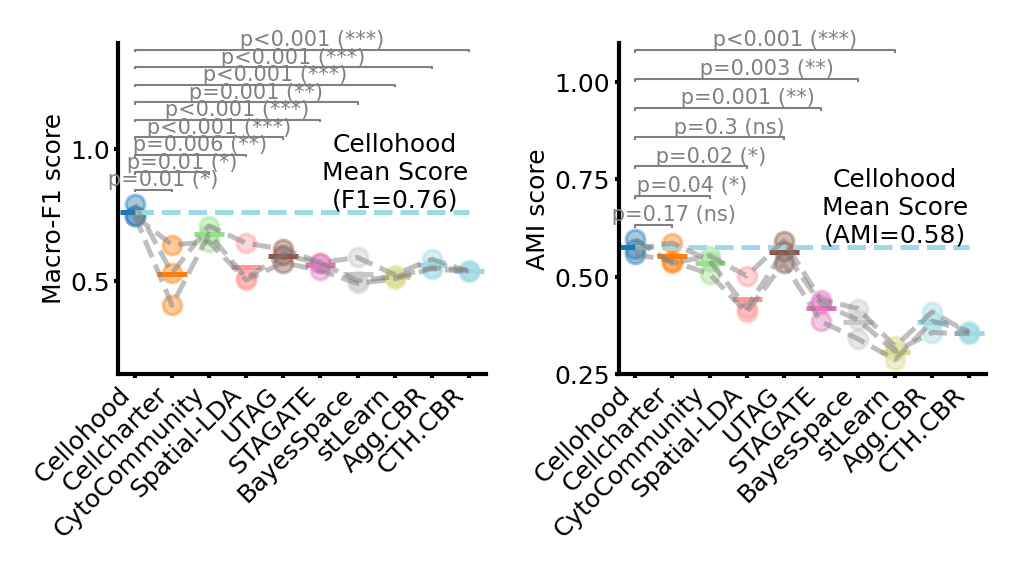

In [37]:
plt.figure(figsize=(3.5, 2), dpi=300)

plt.subplot(1, 2, 1)
for ind_, col in enumerate(ami_scores_df.columns):
    plt.scatter([ind_] * 3, f1_scores_df[col], c=ext_method_cmap(ind_), s=20, alpha=0.4)
    plt.scatter([ind_], [f1_scores_df[col].mean()], marker='_', c=ext_method_cmap(ind_), s=50)
    
    
plt.plot([0, 9], [f1_scores_df['Cellohood'].mean()] * 2, linestyle='dashed', c=method_cmap(ind_))
plt.text(
    7, 
    f1_scores_df['Cellohood'].mean(), 
    f'Cellohood\nMean Score\n(F1={round(f1_scores_df["Cellohood"].mean(), 2)})', 
    ha='center',
    va='bottom',
    size=6
)

for other, x in enumerate(numpy.linspace(0.82, 1.35, len(f1s_p_vals) - 1)):
    AnnoMe(0, other + 1, x + 0.02, get_stars_from_pval(f1s_p_vals[0, other + 1]))
    
plt.ylim([0.15, 1.4])
plt.plot(f1_scores_df.loc[0], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(f1_scores_df.loc[1], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(f1_scores_df.loc[2], c='gray', linestyle='dashed', alpha=0.5)
plt.xticks(rotation=45, size=6, ha='right')
plt.yticks(size=6)
plt.ylabel('Macro-F1 score', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)


plt.subplot(1, 2, 2)

for ind_, col in enumerate(ami_scores_df.columns):
    plt.scatter([ind_] * 3, ami_scores_df[col], c=ext_method_cmap(ind_), s=20, alpha=0.4)
    plt.scatter([ind_], [ami_scores_df[col].mean()], marker='_', c=ext_method_cmap(ind_), s=50)
    
plt.plot([0, 9], [ami_scores_df['Cellohood'].mean()] * 2, linestyle='dashed', c=ext_method_cmap(ind_))
plt.text(7,
         ami_scores_df['Cellohood'].mean(),
         f'Cellohood\nMean Score\n(AMI={round(ami_scores_df["Cellohood"].mean(), 2)})',
         ha='center', va='bottom', size=6)
plt.ylim([0, 1])
    
for other, x in enumerate(numpy.linspace(0.6, 1.05, 7)):
    AnnoMe(0, other + 1, x + 0.028, '   ' + get_stars_from_pval(amis_p_vals[0, other + 1]))
    
plt.ylim([0.25, 1.1])
plt.plot(ami_scores_df.loc[0], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(ami_scores_df.loc[1], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(ami_scores_df.loc[2], c='gray', linestyle='dashed', alpha=0.5)
plt.xticks(rotation=45, size=6, ha='right')
plt.yticks(size=6)
plt.ylabel('AMI score', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)

plt.tight_layout()

## Images With Spatial Directions

In [38]:
IMAGES_PATHS = os.path.join(OTHER_METHOD_PATHS, 'other_figs')

cyto_1 = plt.imread(os.path.join(IMAGES_PATHS, 'Cyto-Balbc3.png'))
cyto_2 = plt.imread(os.path.join(IMAGES_PATHS, 'Cyto-Balbc2.png'))
cyto_3 = plt.imread(os.path.join(IMAGES_PATHS, 'Cyto-Balbc1.png'))

In [39]:
utag_1 = plt.imread(os.path.join(IMAGES_PATHS, 'Utag-Balbc1.png'))
utag_2 = plt.imread(os.path.join(IMAGES_PATHS, 'Utag-Balbc2.png'))
utag_3 = plt.imread(os.path.join(IMAGES_PATHS, 'Utag-Balbc3.png'))

## Cellohood vs GT and other methods

In [40]:
OTHER_METHODS_PATHS = os.path.join(ZENODO_PATH, 'other_methods')
CELLCHARTER_PREDS_PATH = os.path.join(OTHER_METHODS_PATHS, 'Cellcharter_preds.csv')

cellcharter_preds = pandas.read_csv(CELLCHARTER_PREDS_PATH)

## Same + Principal Latent Dimensions

In [41]:
b1_cc_to_color = {
    0: mcolors.CSS4_COLORS['navy'],
    1: mcolors.CSS4_COLORS['magenta'],
    2: mcolors.CSS4_COLORS['red'],
    3: mcolors.CSS4_COLORS['blue'],
    4: mcolors.CSS4_COLORS['yellow'],
    5: mcolors.BASE_COLORS['k'],
    6: mcolors.CSS4_COLORS['orange'],
}

b2_cc_to_color = {
    0: mcolors.CSS4_COLORS['red'],
    1: mcolors.CSS4_COLORS['blue'],
    2: mcolors.CSS4_COLORS['black'],
}

b3_cc_to_color = {
    0: mcolors.CSS4_COLORS['black'],
    1: mcolors.CSS4_COLORS['magenta'],
    2: mcolors.CSS4_COLORS['red'],
    3: mcolors.CSS4_COLORS['blue'],
    4: mcolors.CSS4_COLORS['yellow'],
    5: mcolors.CSS4_COLORS['navy'],
}

/tmp/ipykernel_2526670/1927916714.py:79: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  plt.scatter(
/tmp/ipykernel_2526670/1927916714.py:98: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2526670/1927916714.py:100: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2526670/1927916714.py:214: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2526670/1927916714.py:230: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2526670/1927916714.py:232: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_25266

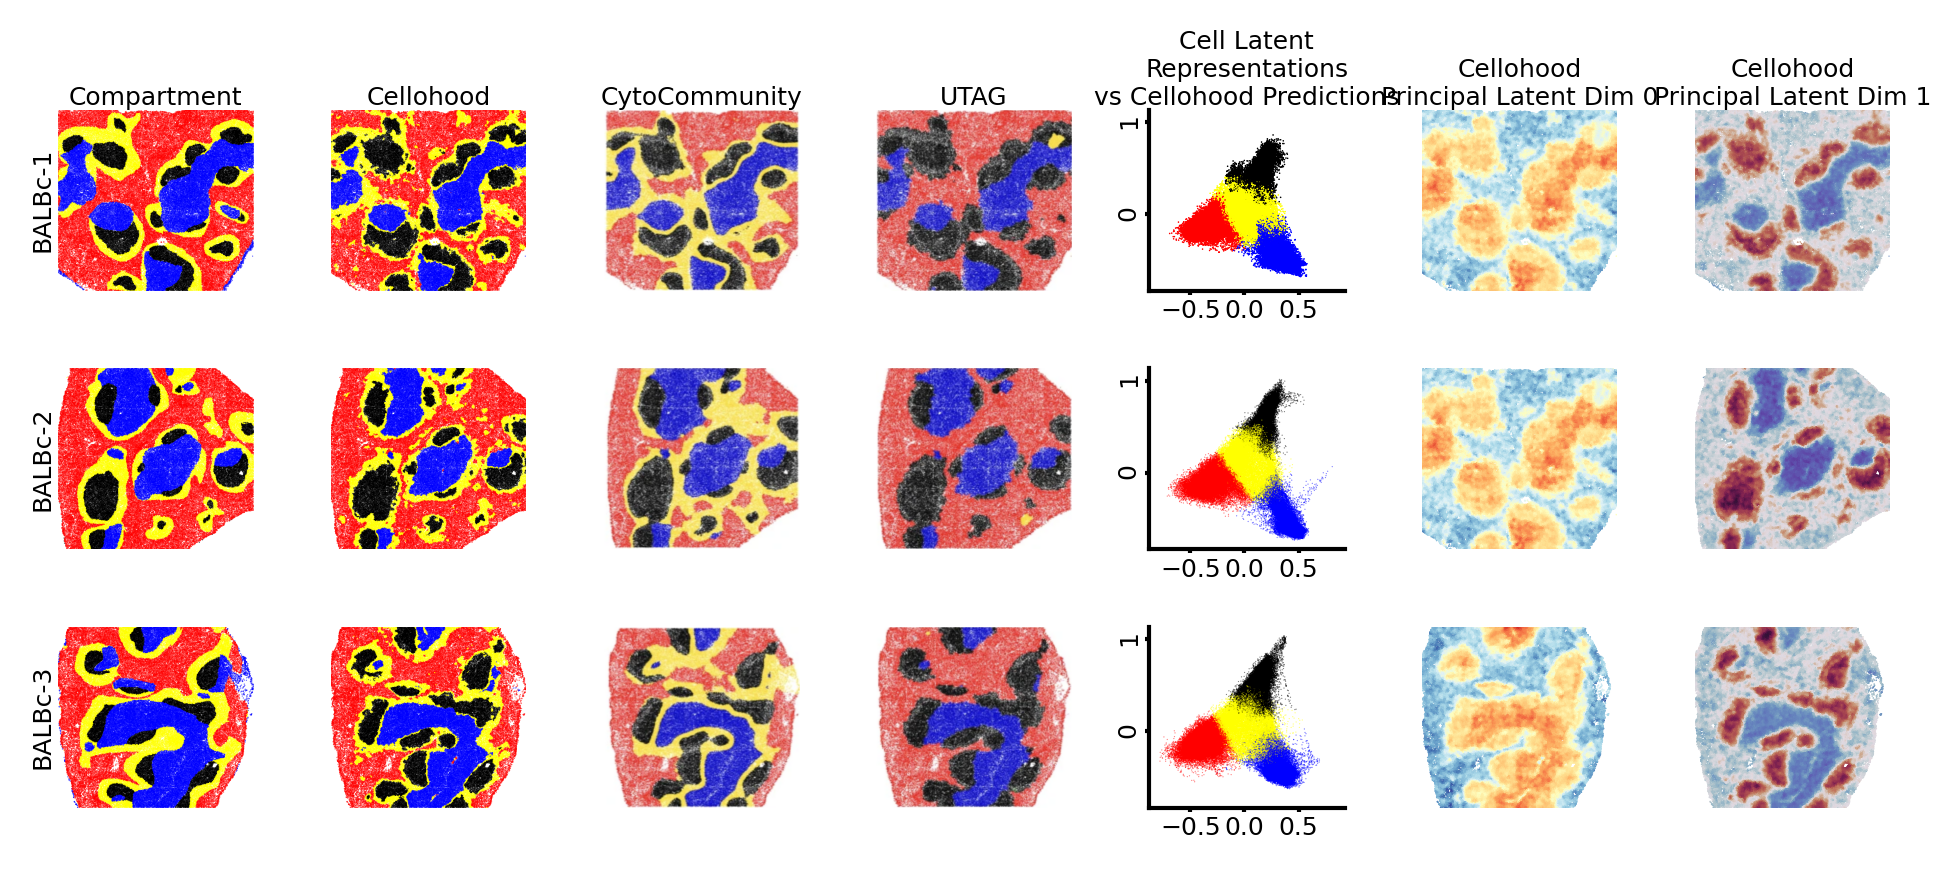

In [42]:
plt.figure(figsize=(6.5, 3), dpi=300)

SCATTER_ALPHA = 0.6

plt.subplot(3, 7, 1)
balbc1_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-1']
balbc1_df = balbc1_all_df[balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('Compartment', size=6, pad=1)
plt.ylabel('BALBc-1', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])


plt.subplot(3, 7, 2)

balbc1_preds = sample_to_predictions['BALBc-1'][
    balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[colors_cc(x) for x in balbc1_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('Cellohood', size=6, pad=1)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 3)

plt.imshow(cyto_1, aspect='auto')
plt.title('CytoCommunity', size=6, pad=1)
plt.axis('off')


plt.subplot(3, 7, 4)

plt.imshow(utag_1, aspect='auto')
plt.title('UTAG', size=6, pad=1)
plt.axis('off')

pd_0_min = balbc_decomposed[:, 0].min()
pd_1_min = balbc_decomposed[:, 1].min()
pd_0_max = balbc_decomposed[:, 0].max()
pd_1_max = balbc_decomposed[:, 1].max()
pd_0_lim = max(abs(pd_0_min), abs(pd_0_max))
pd_1_lim = max(abs(pd_1_min), abs(pd_1_max))

plt.subplot(3, 7, 5)

balbc1_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-1']
balbc1_decomposed = balbc1_all_decomposed[balbc1_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]

plt.scatter(
    x=balbc1_decomposed[:, 0],
    y=balbc1_decomposed[:, 1],
    c=[colors_cc(x) for x in balbc1_preds],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
plt.title('Cell Latent\nRepresentations\nvs Cellohood Predictions', size=6, pad=1)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)

ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.subplot(3, 7, 6)


plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
plt.title('Cellohood\nPrincipal Latent Dim 0', size=6, pad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 7)

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 1],
    s=0.01,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
plt.title('Cellohood\nPrincipal Latent Dim 1', size=6, pad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 8)

balbc2_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-2']
balbc2_df = balbc2_all_df[balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])]


plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=balbc2_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.ylabel('BALBc-2', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 9)

balbc2_preds = sample_to_predictions['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[colors_cc(x) for x in balbc2_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 10)

plt.imshow(cyto_2, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 11)

plt.imshow(utag_2, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 12)

balbc2_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-2']
balbc2_decomposed = balbc2_all_decomposed[balbc2_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]

plt.scatter(
    x=balbc2_decomposed[:, 0],
    y=balbc2_decomposed[:, 1],
    c=[colors_cc(x) for x in balbc2_preds],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)

ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


plt.subplot(3, 7, 13)


plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 14)



plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=balbc2_decomposed[:, 1],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 15)
balbc3_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-3']
balbc3_df = balbc3_all_df[balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.ylabel('BALBc-3', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc3_df['tile.X'].min(), balbc3_df['tile.X'].max()])
ax.set_ylim([balbc3_df['tile.Y'].min(), balbc3_df['tile.Y'].max()])

plt.subplot(3, 7, 16)

balbc3_preds = sample_to_predictions['BALBc-3'][
    balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[colors_cc(x) for x in balbc3_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.set_aspect('auto')
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_xlim([balbc3_df['tile.X'].min(), balbc3_df['tile.X'].max()])
ax.set_ylim([balbc3_df['tile.Y'].min(), balbc3_df['tile.Y'].max()])

plt.subplot(3, 7, 17)

plt.imshow(cyto_3, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 18)

plt.imshow(utag_3, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 19)

balbc3_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-3']
balbc3_decomposed = balbc3_all_decomposed[balbc3_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]

plt.scatter(
    x=balbc3_decomposed[:, 0],
    y=balbc3_decomposed[:, 1],
    c=[colors_cc(x) for x in balbc3_preds],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax.xaxis.set_tick_params(size=1, pad=1)

ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
pos = ax.get_position()
# Create a new position with increased margins
new_pos = [pos.x0 + 0.012, pos.y0, pos.width - 0.024, pos.height]
# Set the new position
ax.set_position(new_pos)


plt.subplot(3, 7, 20)


plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 21)

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 1],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])


plt.tight_layout()

## Latent Representations

of compartments:

/tmp/ipykernel_2526670/2033533535.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2526670/2033533535.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2526670/2033533535.py:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'Cell Latent\nRepresentations\nvs Compartment')

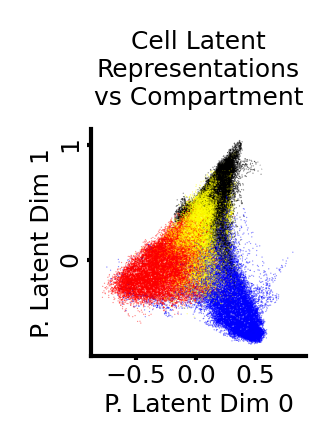

In [43]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 0],
    y=balbc_decomposed[:, 1],
    c=[colors_cc(x) for x in balbc_samples_df_all['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Cell Latent\nRepresentations\nvs Compartment', size=6)

(for supplement):

/tmp/ipykernel_2526670/2085749235.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2526670/2085749235.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2526670/2085749235.py:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'Cell Latent\nRepresentations\nvs Compartment')

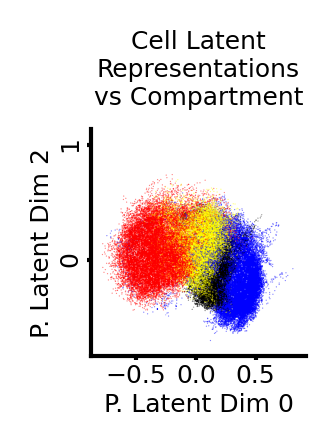

In [44]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 0],
    y=balbc_decomposed[:, 2],
    c=[colors_cc(x) for x in balbc_samples_df_all['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Cell Latent\nRepresentations\nvs Compartment', size=6)

/tmp/ipykernel_2526670/888854300.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2526670/888854300.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2526670/888854300.py:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'Cell Latent\nRepresentations\nvs Ground Truth')

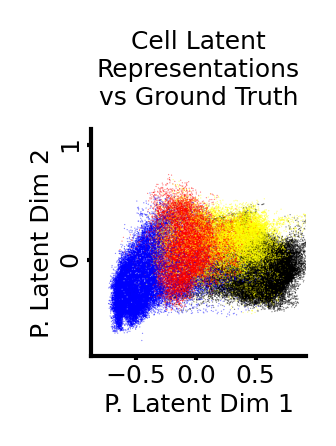

In [45]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 1],
    y=balbc_decomposed[:, 2],
    c=[colors_cc(x) for x in balbc_samples_df_all['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Cell Latent\nRepresentations\nvs Ground Truth', size=6)

against sample (testing the batch effect):

/tmp/ipykernel_2526670/4069653428.py:19: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2526670/4069653428.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Sample')

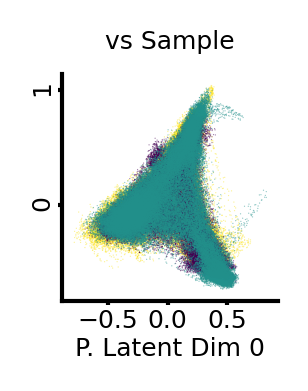

In [46]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 0],
    y=balbc_decomposed[:, 1],
    c=balbc_samples_df_all['sample'].apply(lambda x: int(x.split('-')[-1])),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Sample', size=6)

/tmp/ipykernel_2526670/2518948338.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2526670/2518948338.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Sample')

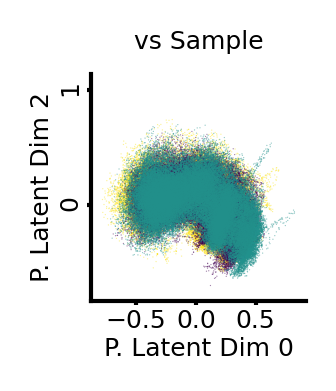

In [47]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 0],
    y=balbc_decomposed[:, 2],
    c=balbc_samples_df_all['sample'].apply(lambda x: int(x.split('-')[-1])),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Sample', size=6)

/tmp/ipykernel_2526670/2324110444.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2526670/2324110444.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Sample')

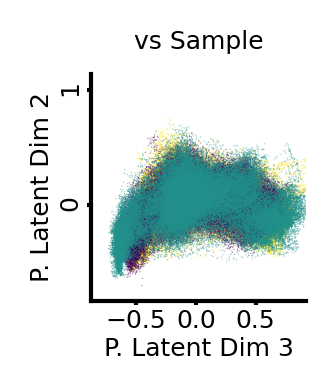

In [48]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 1],
    y=balbc_decomposed[:, 2],
    c=balbc_samples_df_all['sample'].apply(lambda x: int(x.split('-')[-1])),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 3', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Sample', size=6)

## Mouse Level Analysis

Let's start with some housekeeping:

In [49]:
cell_df = bag_cello_df.cell_df

cell_df[DUMMY_COL_NAME] = 1

In [50]:
PREDICTION_CLUSTER_COLUMN = 'Cellohood Neighborhood Cluster'
PREDICTION_75_CLUSTER_COLUMN = 'Cellohood Neighborhood Cluster 75'
CC_CLUSTER_NAME = 'cellohood_neighborhood_cluster'
CELLTYPE_COLNAME = 'CellType'
CELLTYPE_PLOT_NAME = 'Cell Type'

NB_OF_CLUSTERS = 9

Let's have a look at number of clusters selected for different resolutions:

In [51]:
cellohood.summarize_latent_direction_result(latent_direction_result)

Latent Direction Summary:
Variance: 0.5 (dim=3), selected clusters = [11, 16, 24].
Variance: 0.75 (dim=12), selected clusters = [18].
Variance: 1.0 (dim=64), selected clusters = [11, 14, 18, 21, 26].


In paper we analyzed 14 clusters for PLDA.100 (variance: 1.0)

In [52]:
predictions = cellohood.get_latent_directions_predictions(
            latent_direction_result=latent_direction_result,
            explained_variance=1.0,
            selected_number_of_clusters=14,
        )

In [53]:
bag_cello_df.cell_df[PREDICTION_CLUSTER_COLUMN] = bag_cello_df.cell_df[CC_CLUSTER_NAME].apply(
    lambda x: predictions[x])

Now - let's have a look at cell types:

In [54]:
celltype_counts = pandas.pivot_table(
    bag_cello_df.cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc="sum",
).fillna(0)

In [55]:
celltype_percentages = (celltype_counts.T / celltype_counts.sum(axis=1)).T
celltype_percentages.columns.name = CELLTYPE_PLOT_NAME

In [56]:
celltypes = list(celltype_percentages.columns)

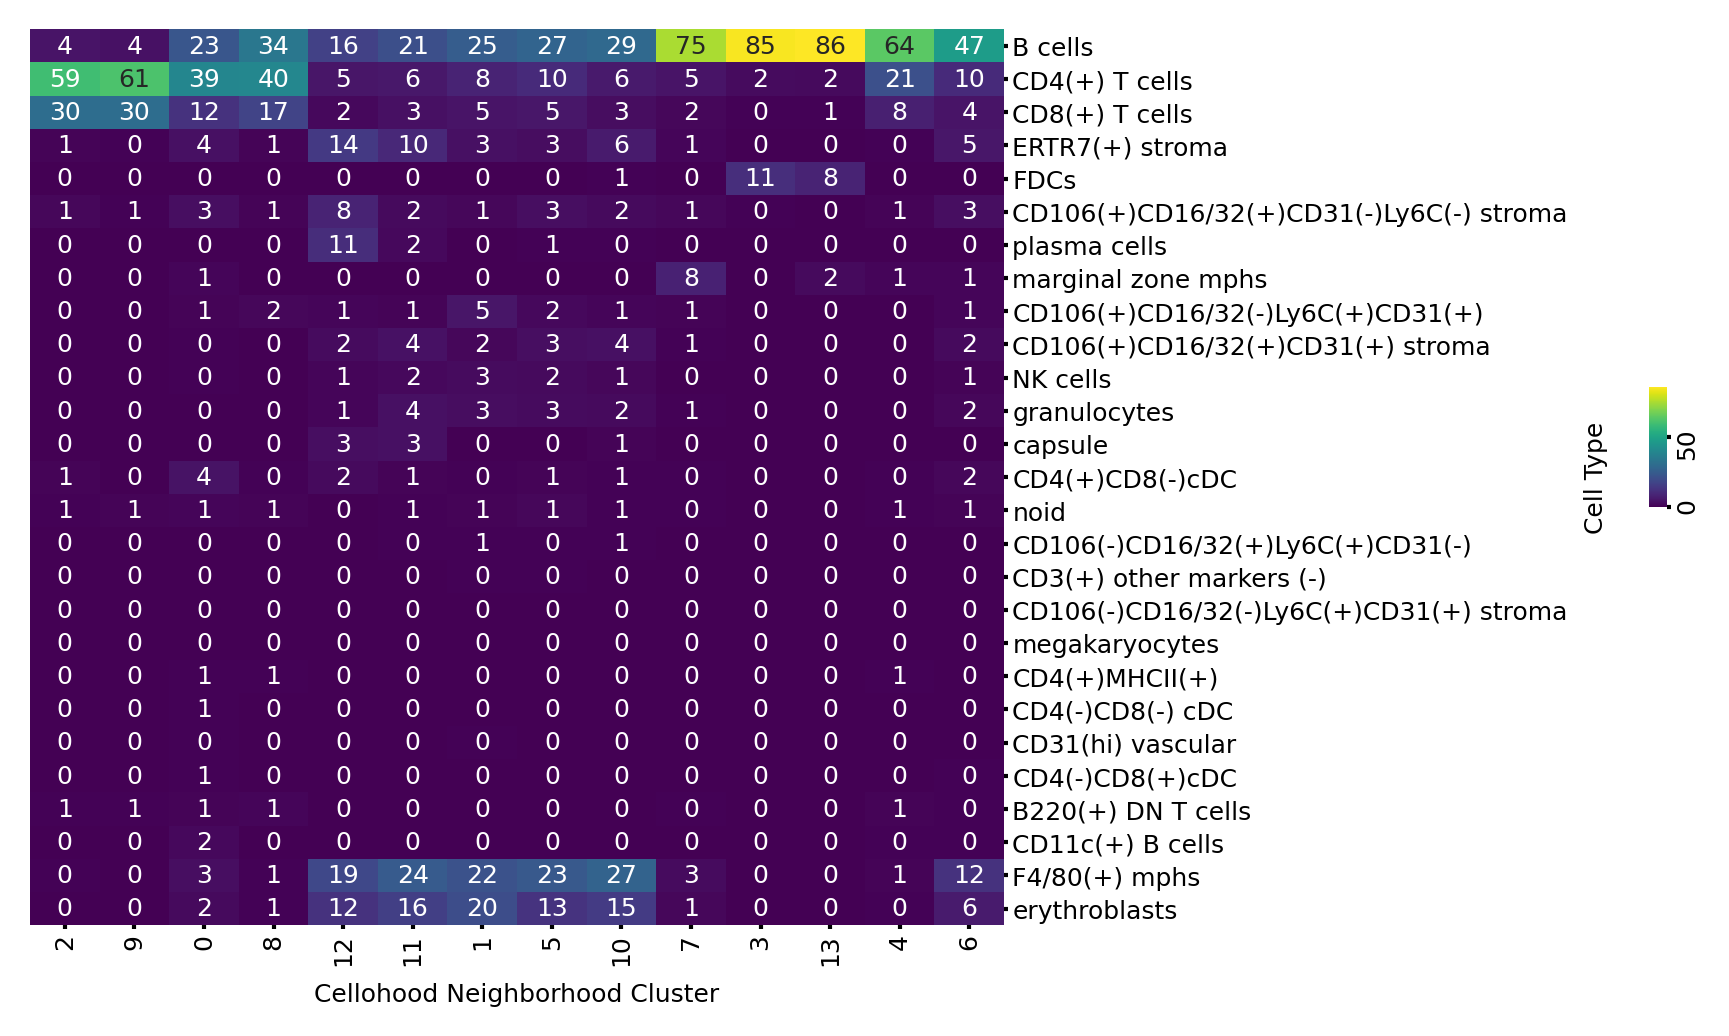

In [57]:
import seaborn as sns

celltype_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)


celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_clustermap.fig.set_size_inches((6, 4))

## Marker analysis

### Cell type level:
For each marker compute the average marker expression for a given cell type:

In [58]:
marker_to_celltype_dfs = {}

MARKERS_CLEAN = MARKER_COL_NAMES
MARKER_PLOT_NAME = 'Markers'
ALL_PLOT_NAME = 'All'


for marker in MARKER_COL_NAMES:
    marker_to_celltype_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to cell type to marker df:

In [59]:
import numpy

marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_celltype_dfs.values()
])

celltype_to_marker_dfs = {
    ct: pandas.DataFrame(
        marker_ct_ipc[:, :, ct_ind],
        index=MARKER_COL_NAMES,
    )
    for ct_ind, ct in enumerate(celltypes)
}

Now - let's rename the markers to their clean names:

In [60]:
celltype_to_marker_dfs_clean = {}


for celltype, cdf in celltype_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

## All marker analysis:

Now let's compute the overall marker distribution across all cells:

In [61]:
all_markers_distribution = bag_cello_df.cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKER_COL_NAMES]
all_markers_distribution -= all_markers_distribution.mean()
all_markers_distribution /= all_markers_distribution.std()
all_markers_distribution.columns = MARKER_COL_NAMES


celltype_to_marker_dfs_clean[ALL_PLOT_NAME] = all_markers_distribution.T

/tmp/ipykernel_2526670/3658460709.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_markers_distribution = bag_cello_df.cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKER_COL_NAMES]


Now let's display the all marker distributions:

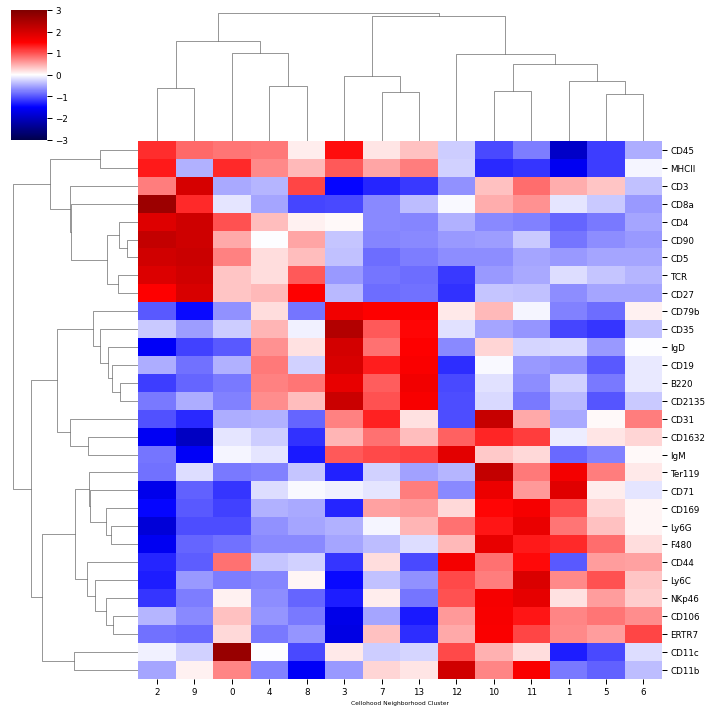

In [62]:
sns.clustermap(all_markers_distribution.T, center=0, cmap='seismic', vmin=-3, vmax=3, yticklabels=True)

Now - let's visualize the Cellohood Neighobrhoods with average markers.

Let's start with providing some handy tools:
- marker colormap:

In [63]:
import matplotlib

marker_color_norm = matplotlib.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = matplotlib.cm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

and a code to transform values to vectors:


In [64]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

In [65]:
all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=celltype_to_marker_dfs_clean[ALL_PLOT_NAME].loc[marker],
        colors=marker_sm,
    )
    for marker in MARKERS_CLEAN
}

all_colors_df = pandas.DataFrame(all_colors_dict)

and visualize CC clusters with average marker distributions:


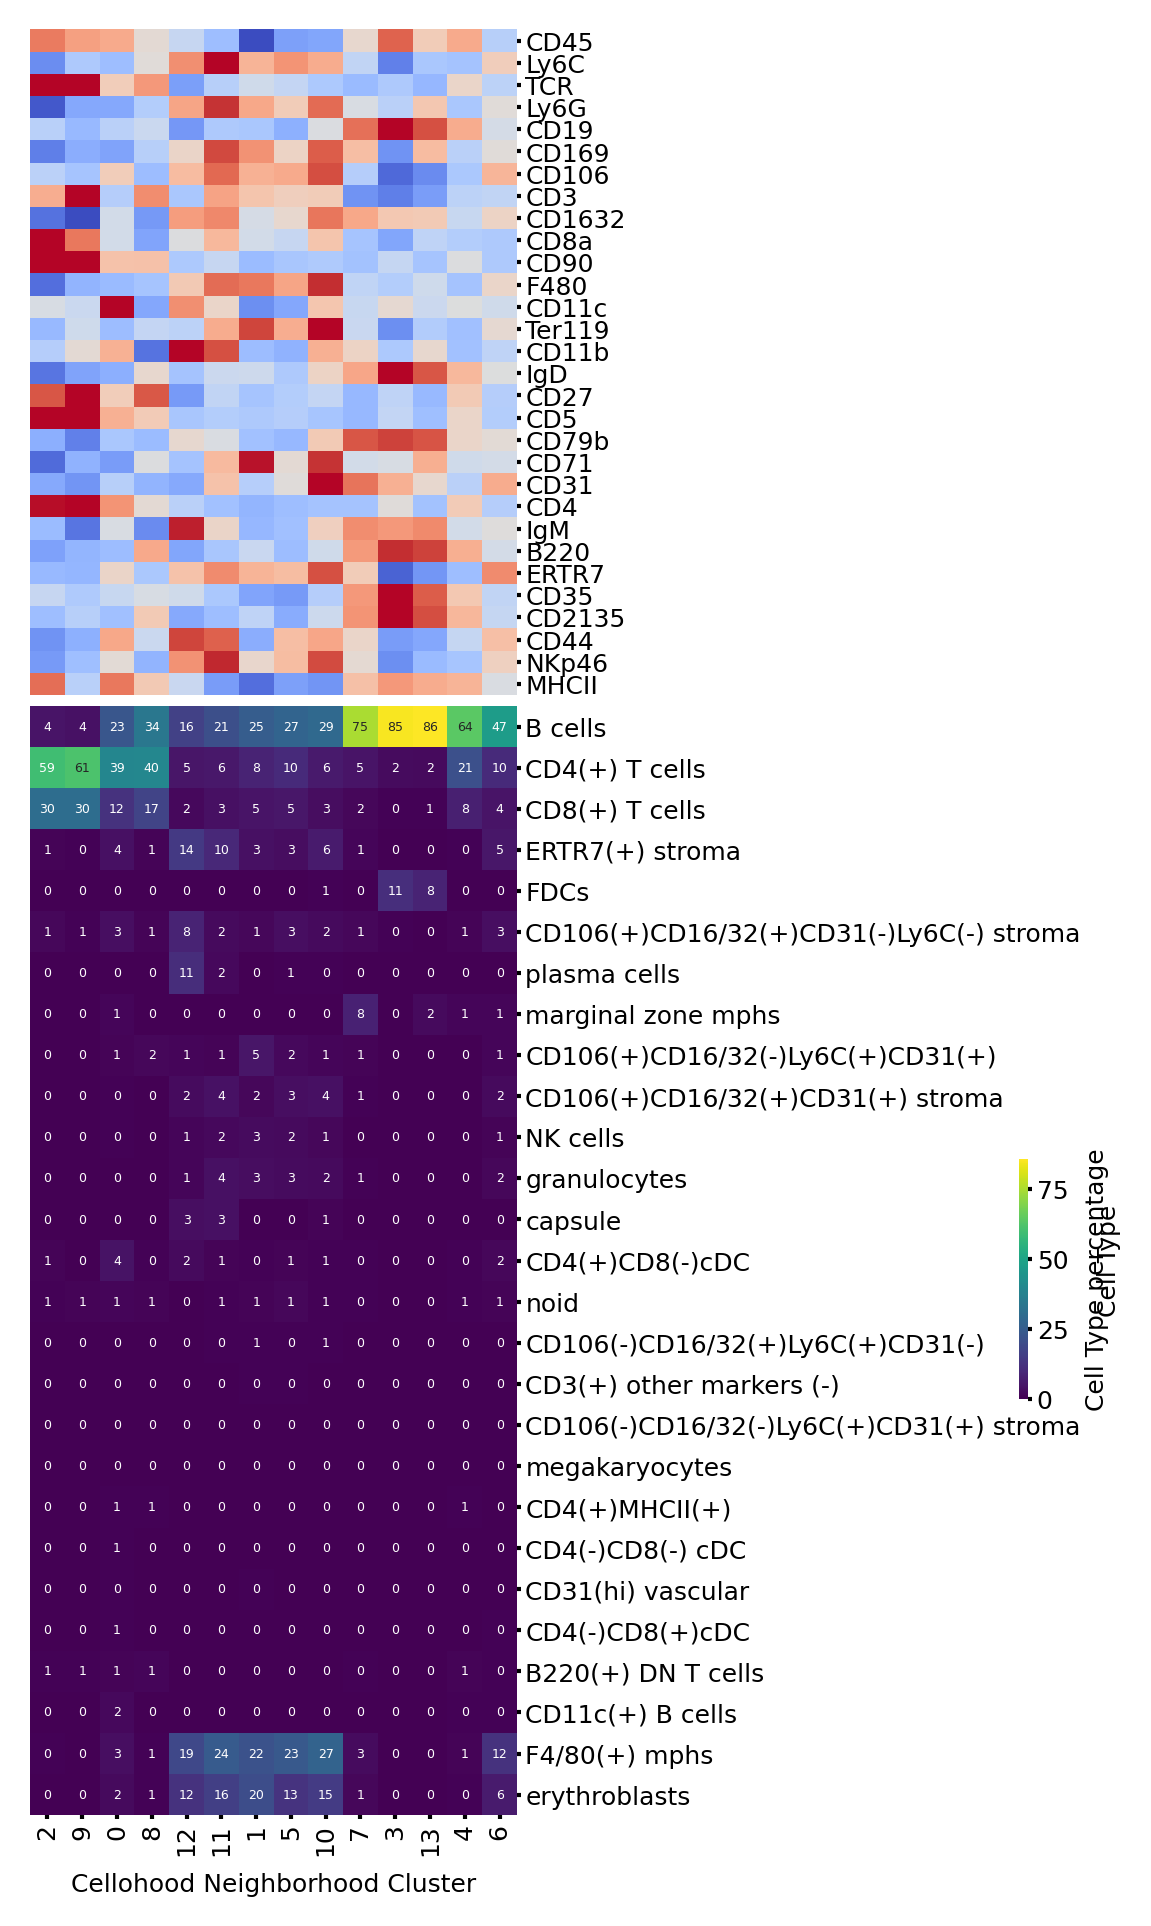

In [66]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)


celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))

Mouse-level CN count analysis:

In [67]:
roi_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=['sample'],
    columns=[PREDICTION_CLUSTER_COLUMN],
    aggfunc="sum",
).fillna(0)

In [68]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

Here - we set the cell type / marker pairs we would like to visualize:

In [69]:
celltypes_to_marker_to_show = {
    'erythroblasts': ['CD71', 'Ter119', 'CD27'],
    'F4/80(+) mphs': ['CD11c', 'CD169'],
    'CD4(+) T cells': ['CD45', 'CD44', 'MHCII', 'CD90', 'CD27'],
    'CD8(+) T cells': ['CD45', 'CD44', 'MHCII', 'CD90'],
    'B cells': ['IgD', 'B220', 'CD45', 'CD79b', 'CD5', 'CD2135', 'MHCII'],
    'All': ['Ly6C', 'Ly6G', 'IgM', 'ERTR7']
}

In [70]:
from collections import defaultdict

celltypes_display_percentage = defaultdict(lambda: 0.1)


celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show
    if ct in celltype_percentages.columns
}

In [71]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

/tmp/ipykernel_2526670/245851321.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_2526670/245851321.py:52: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


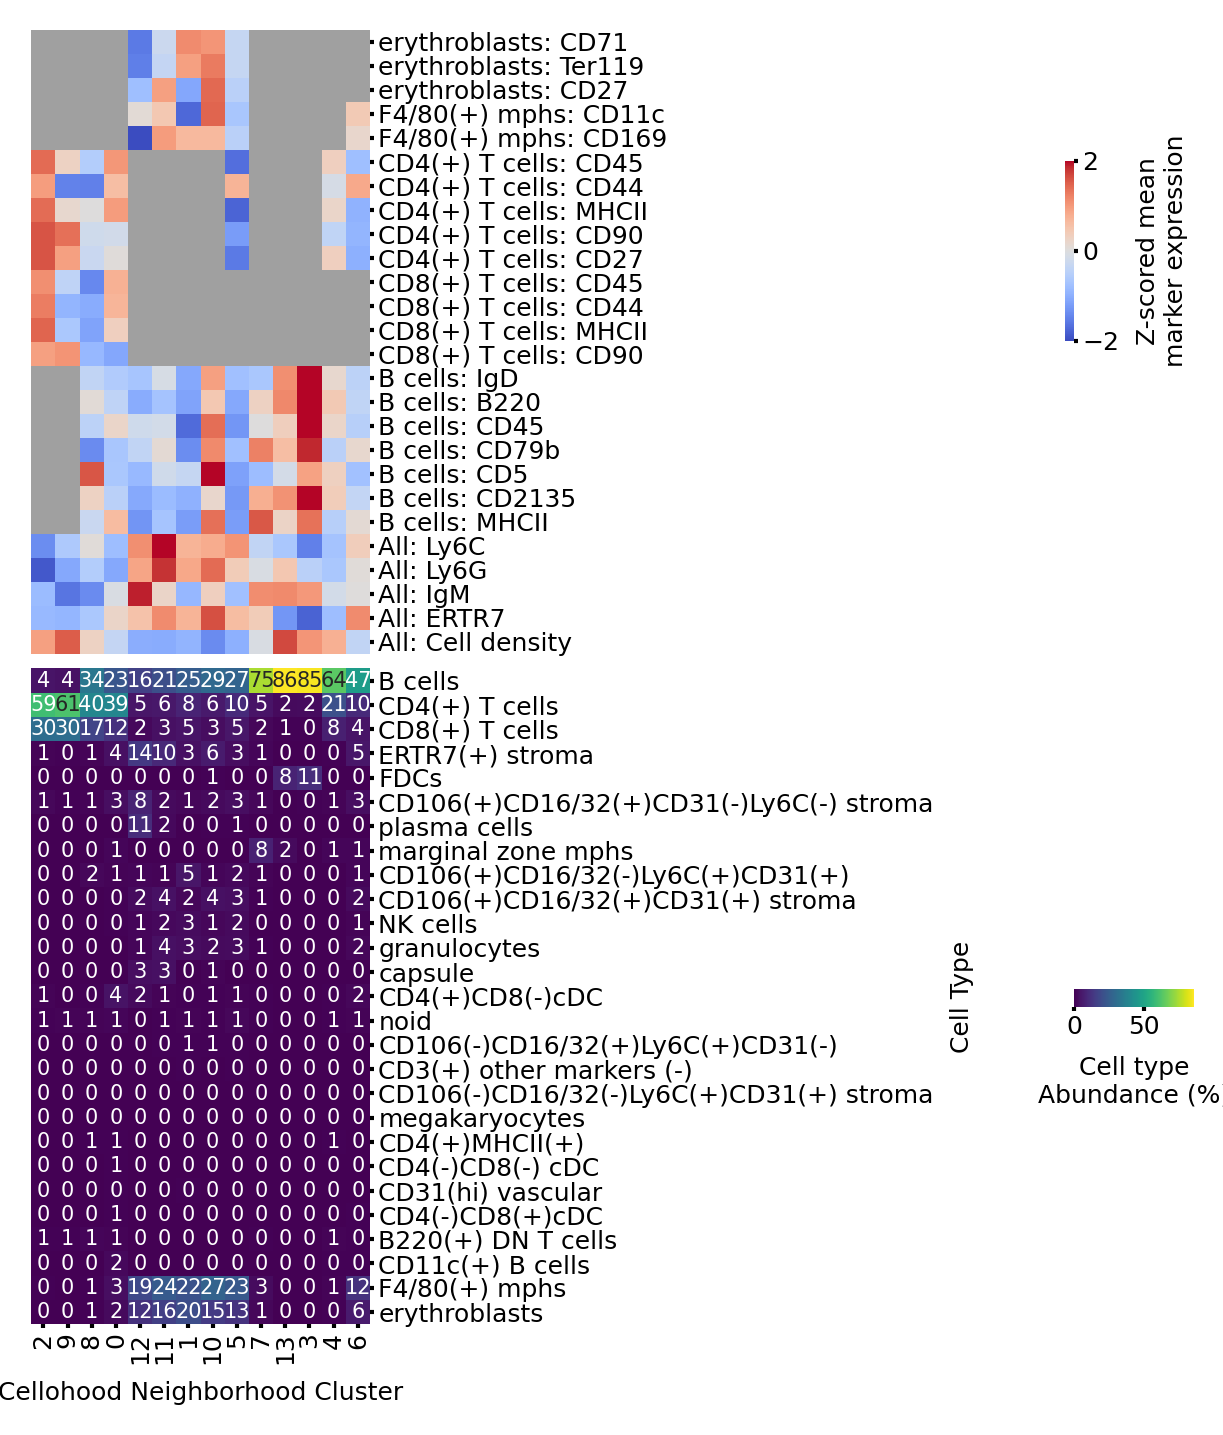

In [72]:
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-celltype_percentages['B cells'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[cc_abundance_std_argsort], 
    annot=True,
    col_cluster=True,
    fmt='.0f',
    cmap='viridis',
    figsize=(5, 7),
    col_colors=cc_marker_ct_colors,
    annot_kws={'size': 5},
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=cc_abundance_std_argsort,
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.25, 0.1, .01],
    cbar_kws={'label': 'Cell type\nAbundance (%)', 'orientation': 'horizontal'}
)


celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((4, 6))
plt.tight_layout()

In [73]:
ct_norm = matplotlib.colors.Normalize(vmin=0, vmax=celltype_percentages.values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = matplotlib.cm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)

In [74]:
max_table = celltype_clustermap.data2d.max(axis=1)

In [75]:
CT_PERCENTAGE_THRESHOLD = 5

full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    if max_table[celltype] < CT_PERCENTAGE_THRESHOLD:
        continue
    full_cc_colors_with_ct[f'{celltype}'] = [
        ct_sm.to_rgba(x) for x in celltype_percentages[celltype]
    ]

In [76]:
healthy_argsort = numpy.argsort(
    (roi_counts.T * (numpy.arange(1, 9 + 1) ** 2)
).sum(axis=1) / roi_counts.T.sum(axis=1))

In [77]:
roi_counts.columns.name = ''

In [78]:
from matplotlib import colors as mcolors

CLUSTER_TO_COLOR = defaultdict(lambda: mcolors.CSS4_COLORS['gray'])
CLUSTER_TO_COLOR[9] = mcolors.CSS4_COLORS['blue']
CLUSTER_TO_COLOR[13] = mcolors.CSS4_COLORS['black']
CLUSTER_TO_COLOR[11] = mcolors.CSS4_COLORS['orangered']
CLUSTER_TO_COLOR[4] = mcolors.CSS4_COLORS['purple']
CLUSTER_TO_COLOR[0] = mcolors.CSS4_COLORS['darkslateblue']
CLUSTER_TO_COLOR[3] = mcolors.CSS4_COLORS['dodgerblue']
CLUSTER_TO_COLOR[12] = mcolors.CSS4_COLORS['deeppink']
CLUSTER_TO_COLOR[6] = mcolors.CSS4_COLORS['yellow']
CLUSTER_TO_COLOR[5] = mcolors.CSS4_COLORS['red']
CLUSTER_TO_COLOR[7] = mcolors.CSS4_COLORS['gray']
CLUSTER_TO_COLOR[8] = mcolors.CSS4_COLORS['olive']
CLUSTER_TO_COLOR[2] = mcolors.CSS4_COLORS['cyan']
CLUSTER_TO_COLOR[1] = mcolors.CSS4_COLORS['hotpink']
CLUSTER_TO_COLOR[10] = mcolors.CSS4_COLORS['magenta']

In [79]:
CLUSTER_ORDER = [
    9, 2, 0, 8, 12, 11, 1, 10, 5, 7, 13, 3, 4, 6
]

for i in range(NB_OF_CLUSTERS):
    if i not in CLUSTER_ORDER:
        CLUSTER_ORDER.append(i)

In [80]:
EXCHANGE_LONG_NAMES = {
    'CD106(+)CD16/32(+)CD31(-)Ly6C(-) stroma': '*',
    'CD106(+)CD16/32(-)Ly6C(+)CD31(+)': '**',
}

In [81]:
full_cc_colors_with_ct.columns = [
    EXCHANGE_LONG_NAMES[col] if col in EXCHANGE_LONG_NAMES else col
    for col in full_cc_colors_with_ct.columns
]

In [82]:
STATE_TO_COLOR = {
    'Healthy': mcolors.CSS4_COLORS['forestgreen'],
    'Early': mcolors.CSS4_COLORS['bisque'],
    'Intermediate': mcolors.CSS4_COLORS['darkorange'],
    'Late': mcolors.CSS4_COLORS['maroon'],
}

In [83]:
sample_colors = pandas.DataFrame(
    [
        STATE_TO_COLOR['Healthy']
    ] * 3 + [
        STATE_TO_COLOR['Early']
    ] * 3 + [
        STATE_TO_COLOR['Intermediate']
    ] * 2 + [STATE_TO_COLOR['Late']],
    index=roi_counts.index,
    #columns=['Lupus Status']
)

In [84]:
roi_counts.index.name = 'Sample'
roi_counts.columns.name = 'Cellular Neighborhood'

In [85]:
LUPUS_ORDER = numpy.argsort(((roi_counts / roi_counts.sum(axis=0)).T * numpy.arange(9)).sum(axis=1))

In [86]:
full_cc_colors_with_ct.insert(loc=26, value=[(1, 1, 1, 1)] * len(full_cc_colors_with_ct), column='')

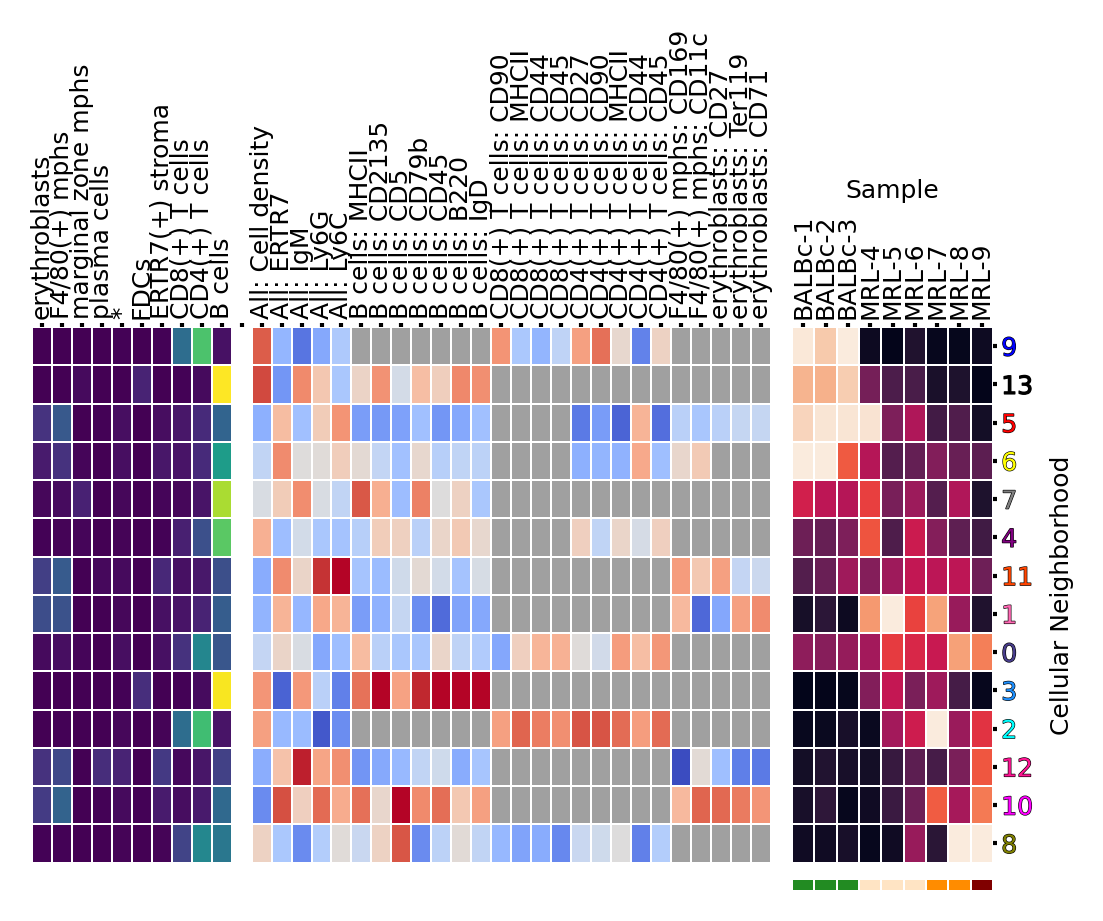

In [87]:
from matplotlib import patheffects


big_l_figure = sns.clustermap(
    roi_counts.T.iloc[LUPUS_ORDER],
    col_cluster=False,
    row_cluster=False,
    row_colors=full_cc_colors_with_ct.iloc[:, ::-1],
    col_colors = sample_colors,
    colors_ratio=0.017,
    cbar_pos=[0.57, 0.73, 0.05, 0.007],
    cbar_kws={'label': 'CN abundance', 'aspect': 10, 'orientation': 'horizontal'},
    xticklabels=True,
    vmax=numpy.quantile(roi_counts.values.flatten(), 0.95),
    linewidth=0.001,
)

big_l_figure.fig.set_size_inches((4.2, 2.8))
big_l_figure.fig.set_dpi(PLOTTING_DPI)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_col_colors.set_yticks([])
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()
big_l_figure.ax_heatmap.yaxis.tick_left()

big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_cbar.set_visible(False)

ax_row_colors = big_l_figure.ax_row_colors
row_box = ax_row_colors.get_position()
big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

big_l_figure.ax_heatmap.yaxis.tick_right()


for ytick in big_l_figure.ax_heatmap.get_yticklabels():
    label_text = ytick.get_text()
    if int(label_text) in CLUSTER_TO_COLOR:
        ytick.set_color(CLUSTER_TO_COLOR[int(label_text)])
        ytick.set_path_effects([
            patheffects.Stroke(linewidth=0.3, foreground='black'),
            patheffects.Normal()
        ])
        #ytick.set_bbox(dict(boxstyle="round,pad=0.3", facecolor='lightgray', alpha=0.7))
        
big_l_figure.ax_heatmap.xaxis.set_label_position('top') 

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.02, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.x0 - 0.017 - row_box.width, row_box.y0, row_box.width, row_box.height])

/tmp/ipykernel_2526670/923936376.py:6: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  plt.scatter(


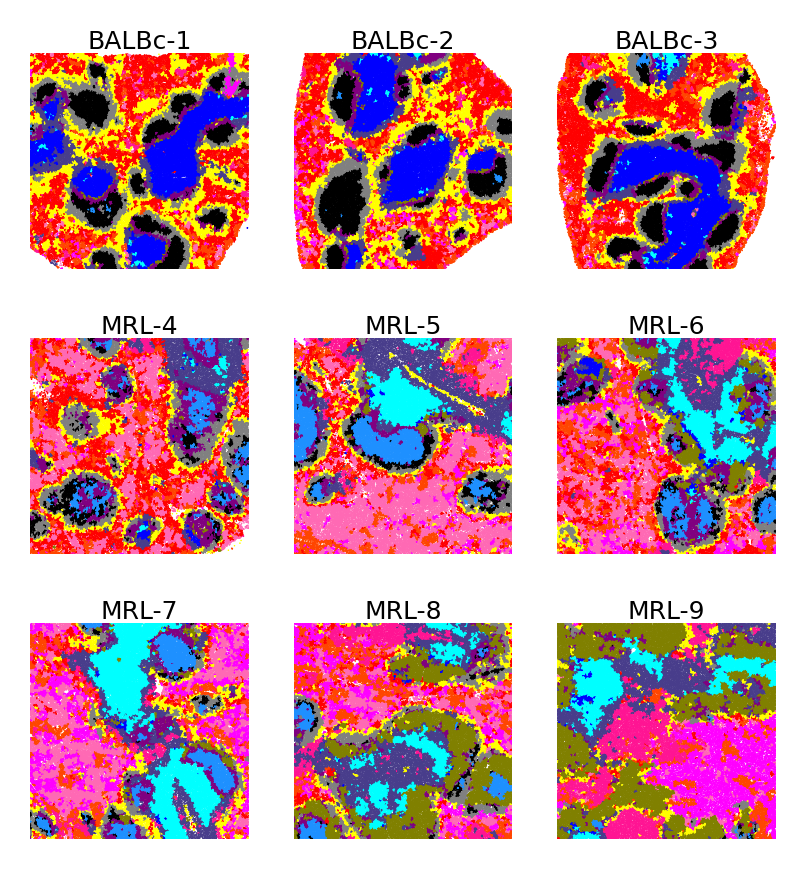

In [88]:
plt.figure(figsize=(6.5 / 7 * 3, 3), dpi=300)

for sample_ind, sample in enumerate(sorted(set(cell_df['sample'])), start=1):
    plt.subplot(3, 3, sample_ind)
    sample_df = cell_df[cell_df['sample'] == sample]
    plt.scatter(
        sample_df['tile.X'],
        sample_df['tile.Y'],
        c=sample_df[PREDICTION_CLUSTER_COLUMN].apply(lambda x: CLUSTER_TO_COLOR[x]),
        s=0.03,
        linewidths=0.2,
        vmax=20,
        vmin=0,
    )
    plt.title(sample, size=6, pad=1)
    plt.axis('off')
    ax = plt.gca()
    ax.spines[['top', 'left']].set_visible(False)
    ax.spines[['bottom', 'right']].set_visible(False)
    _ = ax.set_xticks([])
    _ = ax.set_yticks([])
    ax.set_aspect('auto')
    ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
    ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.tight_layout()

In [89]:
agg_cth_colors_cc_b1 = {
    0: mcolors.CSS4_COLORS['yellow'],
    1: mcolors.CSS4_COLORS['blue'],
    2: mcolors.CSS4_COLORS['black'],
    3: mcolors.CSS4_COLORS['red'],
}


agg_cth_colors_cc_b2 = {
    0: mcolors.CSS4_COLORS['yellow'],
    1: mcolors.CSS4_COLORS['black'],
    2: mcolors.CSS4_COLORS['red'],
    3: mcolors.CSS4_COLORS['blue'],
}

agg_cth_colors_cc_b3 = {
    0: mcolors.CSS4_COLORS['blue'],
    1: mcolors.CSS4_COLORS['black'],
    2: mcolors.CSS4_COLORS['yellow'],
    3: mcolors.CSS4_COLORS['red'],
}

agg_cth_colors_mm_b1 = {
    0: mcolors.CSS4_COLORS['black'],
    1: mcolors.CSS4_COLORS['blue'],
    2: mcolors.CSS4_COLORS['darkblue'],
    3: mcolors.CSS4_COLORS['red'],
    4: mcolors.CSS4_COLORS['yellow'],
}


agg_cth_colors_mm_b2 = {
    0: mcolors.CSS4_COLORS['black'],
    1: mcolors.CSS4_COLORS['blue'],
    2: mcolors.CSS4_COLORS['yellow'],
    3: mcolors.CSS4_COLORS['red'],
}


agg_cth_colors_mm_b3 = {
    0: mcolors.CSS4_COLORS['black'],
    1: mcolors.CSS4_COLORS['blue'],
    2: mcolors.CSS4_COLORS['yellow'],
    3: mcolors.CSS4_COLORS['red'],
}

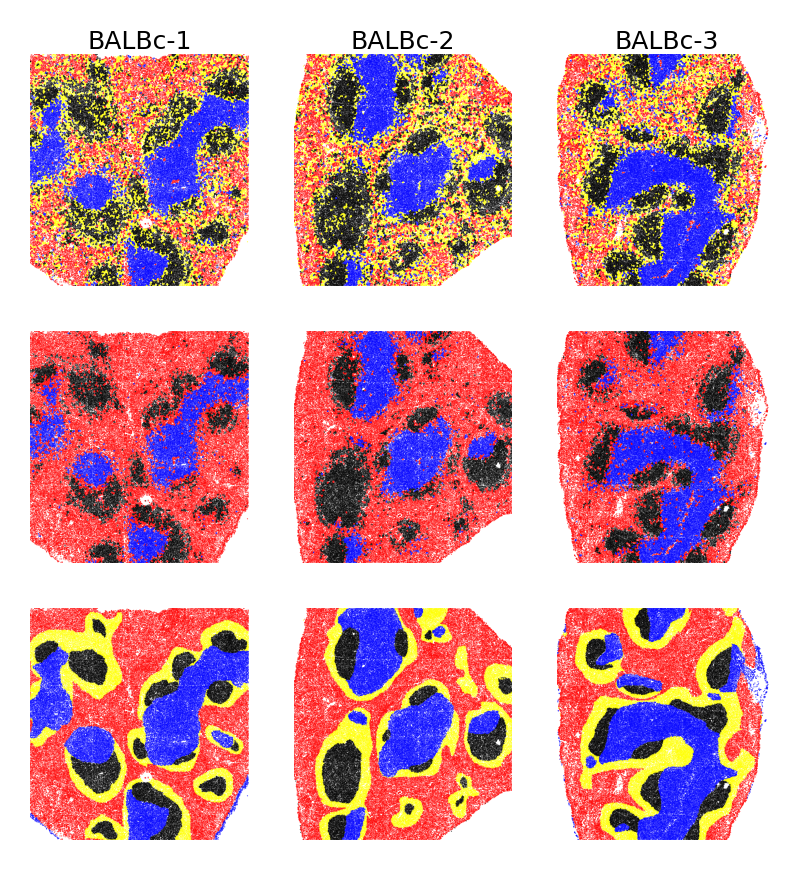

In [90]:
plt.figure(figsize=(6.5 / 7 * 3, 3), dpi=300)

plt.subplot(3, 3, 1)

balbc1_preds_cth = sample_to_predictions_cth['BALBc-1'][
    balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[agg_cth_colors_cc_b1[x] for x in balbc1_preds_cth],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.title('BALBc-1', size=6, pad=1)
plt.ylabel('AGG.CTH')


plt.subplot(3, 3, 2)

balbc2_preds_cth = sample_to_predictions_cth['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[agg_cth_colors_cc_b2[x] for x in balbc2_preds_cth],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.title('BALBc-2', size=6, pad=1)


plt.subplot(3, 3, 3)

balbc3_preds_cth = sample_to_predictions_cth['BALBc-3'][
    balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[agg_cth_colors_cc_b3[x] for x in balbc3_preds_cth],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])

plt.title('BALBc-3', size=6, pad=1)

plt.subplot(3, 3, 4)

balbc1_preds_mm = sample_to_predictions_agg_cbr['BALBc-1'][
    balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[agg_cth_colors_mm_b1[x] for x in balbc1_preds_mm],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.ylabel('AGG.CBR')

plt.subplot(3, 3, 5)

balbc2_preds_mm = sample_to_predictions_agg_cbr['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[agg_cth_colors_mm_b2[x] for x in balbc2_preds_mm],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])


plt.subplot(3, 3, 6)

balbc3_preds_mm = sample_to_predictions_agg_cbr['BALBc-3'][
    balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[agg_cth_colors_mm_b3[x] for x in balbc3_preds_mm],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])


plt.subplot(3, 3, 7)

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[colors_cc(x) for x in balbc1_df['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.ylabel('Ground truth')


plt.subplot(3, 3, 8)

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[colors_cc(x) for x in balbc2_df['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])


plt.subplot(3, 3, 9)

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[colors_cc(x) for x in balbc3_df['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])

plt.tight_layout()

## MISC (for figures):

##  Legends:

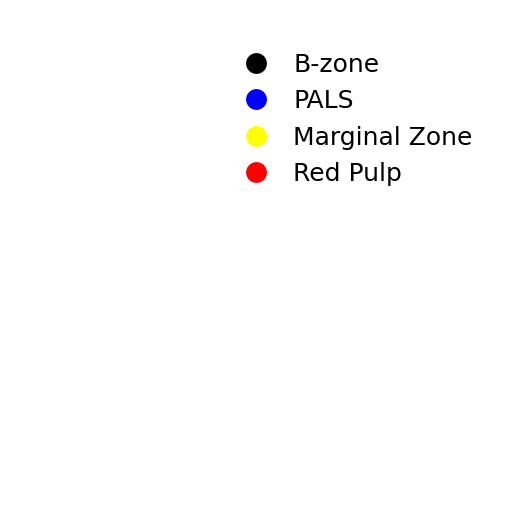

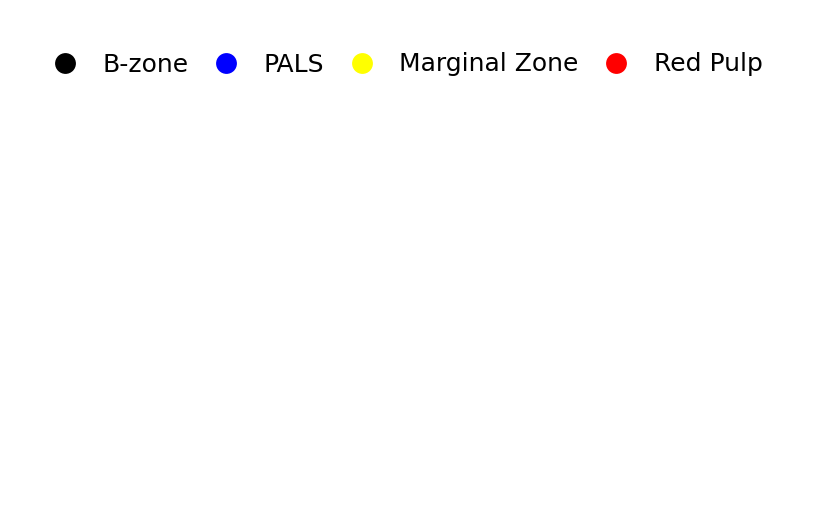

In [91]:
from matplotlib.pyplot import Line2D


legend_elements = [
    Line2D([0], [0], marker='o', markerfacecolor=colors_cc(0), color='w', label='B-zone', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=colors_cc(1), color='w', label='PALS', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=colors_cc(2), color='w', label='Marginal Zone', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=colors_cc(3), color='w', label='Red Pulp', markersize=6),
]

plt.figure(figsize=(2, 2), dpi=300)
plt.legend(
    handles=legend_elements, 
    ncols=1, 
    loc='upper right', 
    fontsize=6, 
    frameon=False,
    labelspacing=0.5,
    handletextpad=0.5,
    columnspacing=0.5,
)
plt.axis('off')
plt.show()


plt.figure(figsize=(2, 2), dpi=300)
plt.legend(
    handles=legend_elements, 
    ncols=4, 
    loc='upper right', 
    fontsize=6, 
    frameon=False,
    labelspacing=0.5,
    handletextpad=0.5,
    columnspacing=0.5,
)
plt.axis('off')
plt.show()

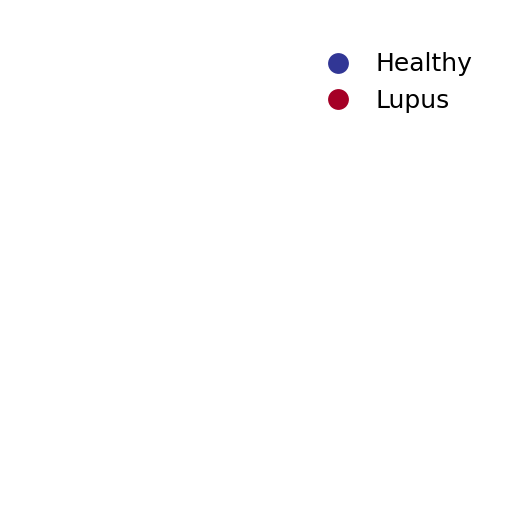

In [92]:
legend_elements = [
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('RdYlBu')(0.999), color='w', label='Healthy', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('RdYlBu')(0), color='w', label='Lupus', markersize=6),
]

plt.figure(figsize=(2, 2), dpi=300)
plt.legend(
    handles=legend_elements, 
    ncols=1, 
    loc='upper right', 
    fontsize=6, 
    frameon=False,
    labelspacing=0.5,
    handletextpad=0.5,
    columnspacing=0.5,
)
plt.axis('off')
plt.show()


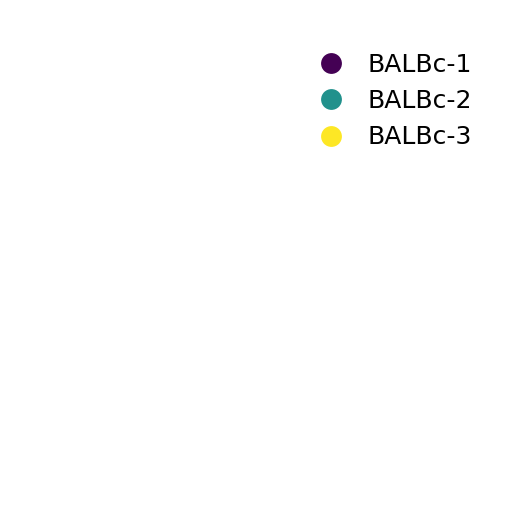

In [93]:
legend_elements = [
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('viridis')(0), color='w', label='BALBc-1', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('viridis')(0.5), color='w', label='BALBc-2', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('viridis')(0.999), color='w', label='BALBc-3', markersize=6),
]

plt.figure(figsize=(2, 2), dpi=300)
plt.legend(
    handles=legend_elements, 
    ncols=1, 
    loc='upper right', 
    fontsize=6, 
    frameon=False,
    labelspacing=0.5,
    handletextpad=0.5,
    columnspacing=0.5,
)
plt.axis('off')
plt.show()


(-0.05500000000000001,
 0.05500000000000001,
 -0.05500000000000001,
 0.05500000000000001)

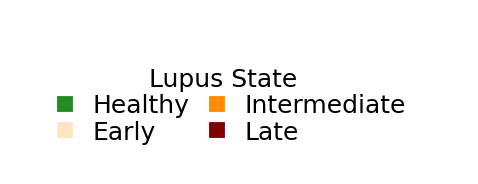

In [94]:
from matplotlib.pyplot import Line2D

plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])

state_colors = list(STATE_TO_COLOR.values())

state_elements = [
    Line2D([0], [0], marker='s', markerfacecolor=state_colors[0], color='w', label='Healthy', markersize=5),
    Line2D([0], [0], marker='s', markerfacecolor=state_colors[1], color='w', label='Early', markersize=5),
    Line2D([0], [0], marker='s', markerfacecolor=state_colors[2], color='w', label='Intermediate', markersize=5),
    Line2D([0], [0], marker='s', markerfacecolor=state_colors[3], color='w', label='Late', markersize=5),
]

plt.legend(
    handles=state_elements, 
    ncols=2, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='Lupus State',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.1,
)
plt.axis('off')

(-0.05500000000000001,
 0.05500000000000001,
 -0.05500000000000001,
 0.05500000000000001)

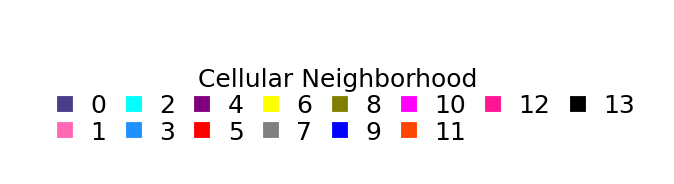

In [95]:
plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])

state_colors = list(STATE_TO_COLOR.values())

state_elements = [
    Line2D([0], [0], marker='s', markerfacecolor=CLUSTER_TO_COLOR[cl], color='w', label=cl, markersize=5)
    for cl in sorted(CLUSTER_TO_COLOR)
]

plt.legend(
    handles=state_elements, 
    ncols=len(state_elements) / 2 + 1, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='Cellular Neighborhood',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.01,
)
plt.axis('off')

## Colorbars

/tmp/ipykernel_2526670/1087159002.py:15: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


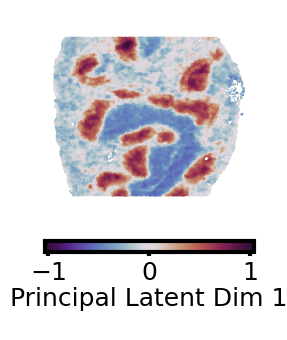

In [96]:
plt.figure(figsize=(0.9, 1.1), dpi=300)
plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 1],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Principal Latent Dim 1', labelpad=0.5)

/tmp/ipykernel_2526670/1720124762.py:15: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


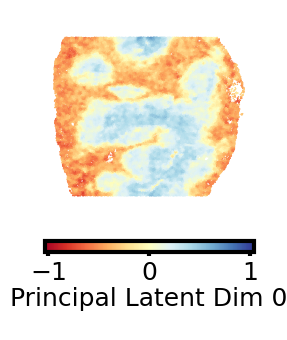

In [97]:
plt.figure(figsize=(0.9, 1.1), dpi=300)
plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='RdYlBu',
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Principal Latent Dim 0', labelpad=0.5)